## Slow Feature Analysis

**Objective:** extract meaningful entities from data without reference to
any specific prior semantic, \
i.e. without any assumptions on the identity of the entities

**Data:** Some time series

**Challenge:** We need to find ...
 * a characteristic qualifying something as a *meaningful entity*
 * a function that can separate noise and random artifacts from meaningful entities

### Slow Feature Analysis - Procedure:
 * What is a **Feature**? In the general sense a feature is a direction in the data space (basis vectors or any linear-combination of basis vectors)
 * What is a **Slow Feature**: Slow features are directions in which the data only changes slowly over time.

 Let's look at SFA for a temporal dataset $X \in \mathbb{R}^{N \times d}$. We have $d$-dimensional data recorded at timesteps $t \in \{1, 2, ..., N\}$, one row per timestep.
 * Finding these directions is done in four main steps:
    1. Expand the data (e.g. as a linear combination of basis functions)
    2. **Whiten** the data: center it, rotate it into the eigenbasis of its covariance matrix $C_X = V D V^T$ and scale every axis to unit variance:
    $$\tilde x(t) = D^{-1/2} V^T \left(x(t) - \vec m\right)$$
      - Now the data has zero mean and identity covariance. This is important: otherwise the direction with the least temporal change could simply be a direction where the data has almost no variance at all.
    3. Empirically compute the local temporal change of the whitened signal, which approximates the **temporal gradient**: 
    $$\tilde x_{temp\_diff}(t) = \tilde x(t+1) - \tilde x(t)$$
      * Next, we compute the covariance matrix of this gradient to find out how the features generally vary over time:
      $$C = \frac{1}{N} \tilde X_{temp\_diff}^T \tilde X_{temp\_diff}$$
    4. The **eigenvectors** of this matrix **provide a new coordinate system** aligned with the principal directions of variance. This reveals along which direction the temporal variation happens a lot and where it happens only very little. So we compute the eigenvectors $\vec a_j$ and eigenvalues $\lambda_j$ of $C$ next. Lastly, to make it useful, we want the direction of least temporal change to line up with our $x$-axis, the direction of second-least temporal change to line up with our $y$-axis and so on... To do that, sort the eigenvectors according to the eigenvalues from small to large (these are the **minor components**), put them as columns into the matrix $A = (\vec a_1, \dots, \vec a_d)$ and transform the whitened data into that eigenbasis of $C$:
    $$SFA(X) = \tilde X A$$
 * The last step aligns the axes of our whitened data with these newly found directions, which is just a rotation! Since the whitened data has identity covariance, any rotation keeps it white, so all slow features still have unit variance and are uncorrelated.
 * If we sort the eigenbasis according to the eigenvalues from low to high, we end up with data where the first dimension corresponds to the direction of least temporal change in the data: our slow features!

In [71]:
import matplotlib.pyplot as plt
import numpy as np

## Generate some data

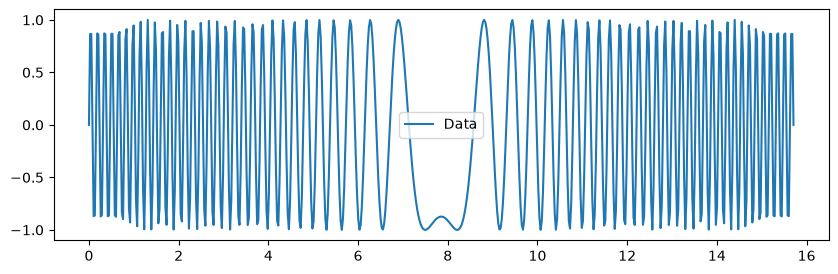

In [89]:
T = 600
ts = np.linspace(0, 5*np.pi, T)

#temp_data = - np.exp(-(6-ts)**2 / 1.5)
temp_data = np.sin(np.sin(ts/5) * 200)
temp_data_noisy = temp_data + np.random.normal(0, 0.05, size=T)

# normalize data
# temp_data = (temp_data - temp_data_noisy.min()) / (temp_data_noisy.max() - temp_data_noisy.min())
# temp_data_noisy = (temp_data_noisy - temp_data_noisy.min()) / (temp_data_noisy.max() - temp_data_noisy.min())

plt.figure(figsize=(10, 3))
#plt.plot(ts, temp_data_noisy, label="Noisy Data")
plt.plot(ts, temp_data, label="Data")
plt.legend()
plt.show()

## Slow Features?

What is the slow feature in this 1-dimensional signal above?

<details>
  <summary>Answer</summary>
Since slow features are directions in the data space that change slowly over time, in the above picture it has to be the amplitude which is our only direction.
The slow feature should therefore simply be the amplitude and we are done, the amplitude is already the y-axis.
So the 1D simple linear SFA only performs whitening:
</details>

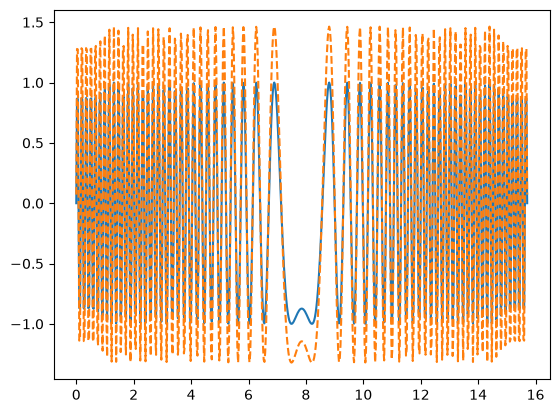

In [73]:
x = temp_data[:,None]

# Whitening:
x = x - x.mean(0)
var = np.var(x)
sfa_out = x / np.sqrt(var)

plt.plot(ts, temp_data)
plt.plot(ts, sfa_out, linestyle='--')
plt.show()

## Only Amplitudes?

What about frequency of the data? Could this also be an SF?

<details>
  <summary>Answer</summary>
  Frequency is not a feature of the data point - so far only amplitude is - but of temporal dynamics. 
  We could use an expansion of the signal to capture frequency.
  
  To make frequency visible, every data point becomes a window of the signal:
  $$\vec x(t) = \big(x(t-5), \dots, x(t+4)\big) \in \mathbb R^{10}$$
</details>

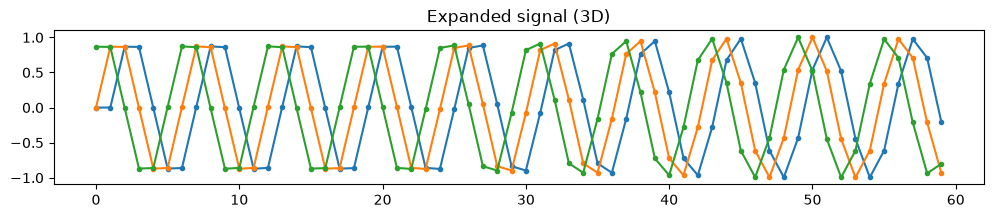

In [74]:
def expansion(x, n=6):
    return np.stack([ np.roll(x, -i + n//2) for i in range(n) ], axis=-1)

plt.figure(figsize=(12, 2)); plt.title('Expanded signal (3D)'); _ = plt.plot(expansion(temp_data, 3)[:60], '-o', markersize=3)

Here, in order to capture frequency, we stack time-shifted versions of the same signal. \
The rate at which these features will change should be proportional to the frequency. 
The expansion will return higher dimensional data, so the whitening becomes a bit more involved. \
Here are the steps:
1) Center the data as before
2) Compute covariance matrix to find directions of feature correlation
3) Compute eigenvectors that show where data gets *pushed* to
3) Rotate data into the eigenbasis to align these directions with the $x$-$y$-plane
4) Now the covariance matrix is diagonal, lastly, scale with eigenvectors (sqare-root to convert from variance to standard deviation)

In [ ]:
# Expand Data (non-)linearly
x = expansion(temp_data, n=2)

# Center around zero (same as in 1D)
x = x - x.mean(0)
# We want to turn the covariance of the data into a unit-diagonal matrix
cov = np.cov(x, rowvar=False)
eigvals, eigvecs = np.linalg.eigh(cov)
order_idx = np.argsort(eigvals)[::-1]

x_white_unscaled = x @ eigvecs[:,order_idx]
x_white = x_white_unscaled / np.sqrt(eigvals[order_idx])
np.cov(x_white, rowvar=False).round(2)

array([[ 1., -0.],
       [-0.,  1.]])

## Visualization of Whitening

array([[ 1., -0.],
       [-0.,  1.]])

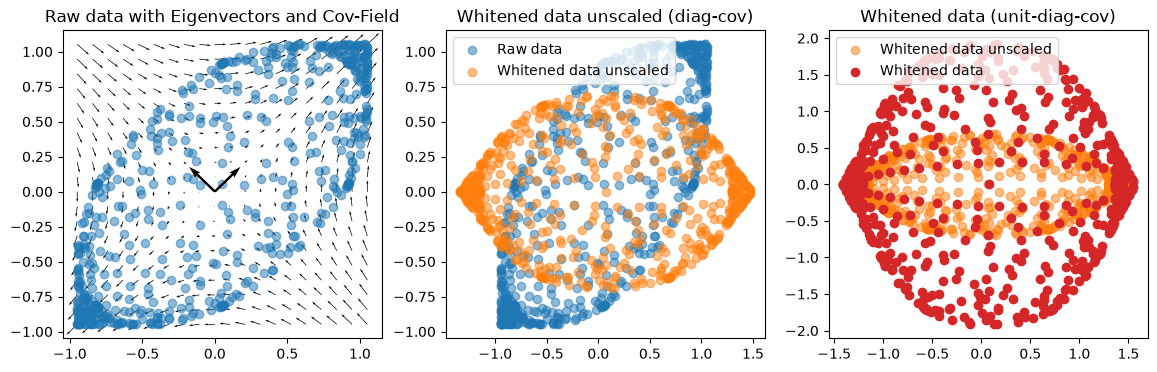

In [76]:
fig, axs = plt.subplots(1, 3, figsize=(14, 4))

xs = np.linspace(x.min(), x.max(), 20)
xs_ys = np.stack(np.meshgrid(xs, xs), -1).reshape(-1, 2)
cov_scaled = cov / cov.max(0, keepdims=True)
xsc_ysc = (xs_ys[:,None] @ cov_scaled[:2,:2]).squeeze()

axs[0].set_title('Raw data with Eigenvectors and Cov-Field')
axs[0].quiver(*xs_ys.T, *(xsc_ysc-xs_ys).T, width=0.005, units='xy', angles='xy')
axs[0].scatter(*x[:,:2].T, alpha=0.5)
axs[0].quiver(*x.mean(0)[:2], *eigvecs[:,np.argsort(eigvals)[::-1]][:2,0], scale=4, units='xy', angles='xy')
axs[0].quiver(*x.mean(0)[:2], *eigvecs[:,np.argsort(eigvals)[::-1]][:2,1], scale=4, units='xy', angles='xy')

axs[1].set_title('Whitened data unscaled (diag-cov)')
axs[1].scatter(*x[:,:2].T, alpha=0.5, label='Raw data')
axs[1].scatter(*x_white_unscaled[:,:2].T, alpha=0.5, label='Whitened data unscaled')
axs[1].legend()

axs[2].scatter(*x_white_unscaled[:,:2].T, alpha=0.5, color='C1', label='Whitened data unscaled')
axs[2].scatter(*x_white[:,:2].T, color='C3', label='Whitened data')
axs[2].set_title('Whitened data (unit-diag-cov)')
axs[2].legend()
np.cov(x_white, rowvar=False).round(2)

In [77]:
def whiten(x):
    # Center around zero (same as in 1D)
    x = x - x.mean(0)
    # We want to turn the covariance of the data into a unit-diagonal matrix
    cov = np.cov(x, rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(cov)
    # find the ordering from largest to lowest eigenvalue
    order_idx = np.argsort(eigvals)[::-1]
    # transform the data into the eigenbasis in the ordering found above
    x_white_unscaled = x @ eigvecs[:,order_idx]
    # Scale: eigenvalues represent the variance, we convert 
    # it to standard deviation via the square-root
    return x_white_unscaled / np.sqrt(eigvals[order_idx])

Text(0.5, 0, 'Time [sec]')

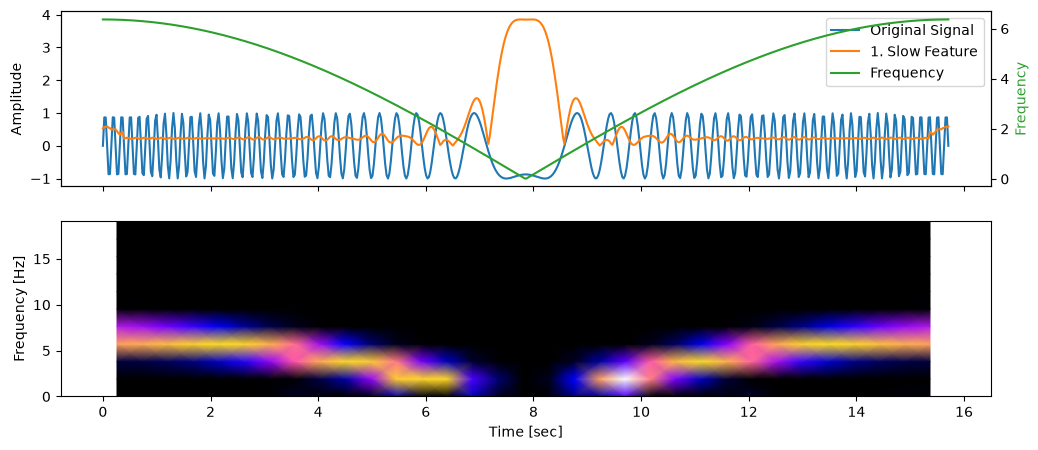

In [ ]:
# This is the SFA

def g(x):
    # 1. Whiten the data
    x_white = whiten(x)
    # 2. Compute the temporal gradient (how data changes with time)
    temp_diff = x_white[1:] - x_white[:-1]
    # 3. Compute covariance matrix to find correlations of variation over time
    cov = np.cov(temp_diff, rowvar=False)
    # 4. Eigenvectors show the principal directions of temporal variation
    #    Eigenvalues show the strangth of temporal variation
    eigvals, eigvecs = np.linalg.eigh(cov)
    # 5. Sort from low to high
    idx = np.argsort(eigvals)
    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]
    # Transform the data into the eigenbasis, now the first dimension of the data
    # Is aligned with the direction of lowest temporal variation, the second 
    # with second lowest.
    return x_white @ eigvecs

# Use the extension that we came up with to represent frequency in each data point
x = expansion(temp_data, n=30)
# Apply SFA
sfa = g(x)

# Visualize!
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
l1, = ax[0].plot(ts, temp_data, color='C0', label='Original Signal')
l2, = ax[0].plot(ts, np.abs(sfa[:,0]), color='C1', label='1. Slow Feature')

# This is the true instantaneous frequency of our signal
f_inst = (1 / (2 * np.pi)) * 200 / 5 * np.cos(ts / 5)
l3, = ax[0].twinx().plot(ts, np.abs(f_inst), color='C2', label='Frequency')

# plot labels
ax[0].set_ylabel('Amplitude')
plt.gca().set_ylabel('Frequency', color='C2')
ax[0].legend(handles=[l1, l2, l3], loc='upper right')

from scipy.signal import spectrogram
f, t, Sxx = spectrogram(temp_data, window='hann', fs=1/(ts[1] - ts[0]), nperseg=20, nfft=20)
ax[1].pcolormesh(t, f, Sxx, shading='gouraud', cmap='gnuplot2')
ax[1].set_ylabel('Frequency [Hz]'); ax[1].set_xlabel('Time [sec]')

The spectrogram shows the frequency over time. It’s our ground truth, and the slow feature reacts exactly where the frequency drops.

# Inverse SFA

Text(0.5, 0, 'Time [sec]')

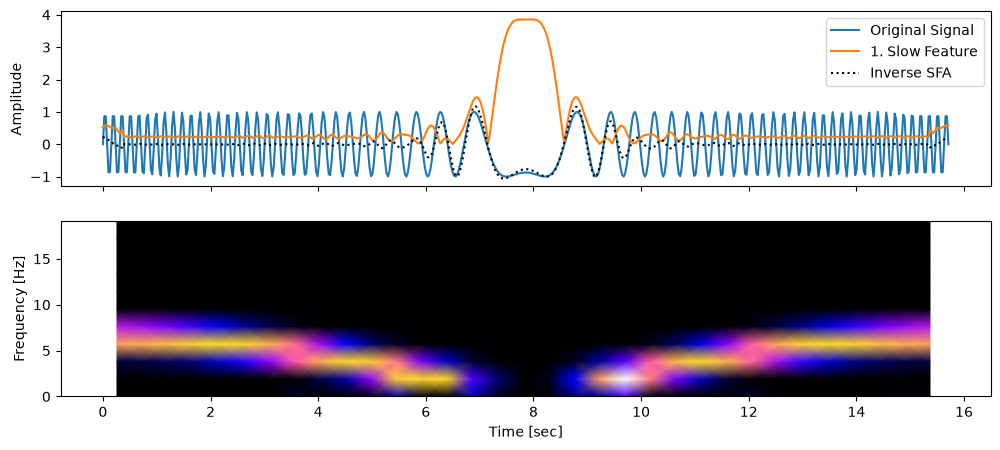

In [95]:
def expansion(x, n=6):
    return np.stack([ np.roll(x, -i + n//2) for i in range(n) ], axis=-1)

def whiten(x):
    # Center around zero (same as in 1D)
    x_mean = x.mean(0)
    x = x - x_mean
    # We want to turn the covariance of the data into a unit-diagonal matrix
    cov = np.cov(x, rowvar=False)
    eigvals, eigvecs = np.linalg.eigh(cov)
    # find the ordering from largest to lowest eigenvalue
    order_idx = np.argsort(eigvals)[::-1]
    # transform the data into the eigenbasis in the ordering found above
    x_white_unscaled = x @ eigvecs[:,order_idx]
    # Scale: eigenvalues represent the variance, we convert 
    # it to standard deviation via the square-root
    x_whitened = x_white_unscaled * (eigvals[order_idx])**-0.5

    def inverse_whiten(x_whitened):
        x_whitened_unscaled = x_whitened * np.sqrt(eigvals[order_idx])
        x = x_whitened_unscaled @ eigvecs[:,order_idx].T # the inverse of the eigenvector basis eigvecs is the transposed since it is orthonormal
        x = x + x_mean
        return x
    
    return x_whitened, inverse_whiten

def g(x):
    # This is the SFA
    # 1. Whiten the data
    x_white, inverse_whiten = whiten(x)
    # 2. Compute the temporal gradient (how data changes with time)
    temp_diff = x_white[1:] - x_white[:-1]
    # 3. Compute covariance matrix to find correlations of variation over time
    cov = np.cov(temp_diff, rowvar=False)
    # 4. Eigenvectors show the principal directions of temporal variation
    #    Eigenvalues show the strangth of temporal variation
    eigvals, eigvecs = np.linalg.eigh(cov)
    # 5. Sort from low to high
    idx = np.argsort(eigvals)
    eigvals = eigvals[idx]
    eigvecs = eigvecs[:, idx]
    # Transform the data into the eigenbasis, now the first dimension of the data
    # Is aligned with the direction of lowest temporal variation, the second 
    # with second lowest.

    def inverse_g(sfa_encoding):
        in_dim = sfa_encoding.shape[-1]
        x_white = sfa_encoding @ eigvecs[:,:in_dim].T
        return inverse_whiten(x_white)

    return x_white @ eigvecs, inverse_g

# Use the extension that we came up with to represent frequency in each data point
x = expansion(temp_data, n=30)
# Apply SFA
sfa, inverse_g = g(x)

K = 3 # 30 vs 10 vs 3
inverse_sfa = inverse_g(sfa[:,:K])

# Visualize!
fig, ax = plt.subplots(2, 1, figsize=(12, 5), sharex=True)
l1, = ax[0].plot(ts, temp_data, color='C0')
l2, = ax[0].plot(ts, np.abs(sfa[:,0]), color='C1')
l3, = ax[0].plot(ts, inverse_sfa[:,15], color='k', linestyle=':')
ax[0].set_ylabel('Amplitude')
_ = ax[0].legend([l1, l2, l3], ['Original Signal', '1. Slow Feature', 'Inverse SFA'], loc='upper right')
from scipy.signal import spectrogram
f, t, Sxx = spectrogram(temp_data, window='hann', fs=1/(ts[1] - ts[0]), nperseg=20, nfft=20)
ax[1].pcolormesh(t, f, Sxx, shading='gouraud', cmap='gnuplot2')
ax[1].set_ylabel('Frequency [Hz]'); ax[1].set_xlabel('Time [sec]')